# 02 · Monthly series and STL decomposition

**Question.** How do monthly recorded counts of each crime group evolve over 2022–2025: what is level, trend and seasonality, how strong is each component, and is there a monotonic trend?

**Methods and libraries.**
- **STL** — Seasonal-Trend decomposition using Loess (Cleveland, R.B., Cleveland, W.S., McRae, J.E. & Terpenning, I. 1990, *J. Official Statistics* 6(1)), `statsmodels.tsa.seasonal.STL` with `period=12`, `robust=True` (robust loess weights, so single outlying months do not bend trend/seasonal), statsmodels default windows (seasonal = 7, trend = next odd integer ≥ 1.5·period / (1 − 1.5/seasonal)).
- **Strength of trend / seasonality** — Wang, X., Smith, K. & Hyndman, R.J. (2006), *Data Mining and Knowledge Discovery* 13(3); Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* 3rd ed. (FPP3), §4.3. No statsmodels function returns these; the two formulas are written out below.
- **Mann–Kendall trend test + Sen's slope** — Mann (1945) *Econometrica* 13; Kendall (1975) *Rank Correlation Methods*; Sen (1968) *JASA* 63; `pymannkendall` (Hussain & Mahmud 2019, *JOSS* 4(39)). `original_test` (assumes independent months), `hamed_rao_modification_test` (variance corrected for autocorrelation; Hamed & Rao 1998, *J. Hydrology* 204) and `seasonal_test` with period 12 (Hirsch, Slack & Smith 1982, *Water Resources Research* 18(1); compares each calendar month only with itself, so seasonality cannot masquerade as trend).

**Data.** Two monthly series per group (48 months, 2022-01 … 2025-12, occurrence date):
1. **all bulletins** of the group, geocoded or not: `Warehouse.counts(CrimeQuery(crime_group=g, unit="city", time_unit="month"))` (the temporal step includes `sexual`, which has no coordinates); `all` = every bulletin in the window;
2. **in-tract** (spatial event set): `Warehouse.counts(CrimeQuery(crime_group=g, time_unit="month"))` summed over tracts.

STL, strengths and trend tests are run on both; the component plots show the all-bulletin series.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
from statsmodels.tsa.seasonal import STL

from crime.core.config import DATE_END, DATE_START, NOTEBOOK_OUTPUTS_DIR
from crime.data import SPATIAL_GROUPS as GROUPS
from crime.data import TEMPORAL_GROUPS, CrimeQuery, Warehouse

OUT = NOTEBOOK_OUTPUTS_DIR / "02_stl"
OUT.mkdir(parents=True, exist_ok=True)
PERIOD = 12          # months per seasonal cycle
ROBUST = True        # robust loess (Cleveland et al. 1990, §3)
ALPHA = 0.05

GROUP_COLORS = {"all": "#2a78d6", "property": "#eb6834", "bodily_harm": "#1baf7a",
                "traffic": "#eda100", "drug": "#e87ba4", "violent": "#008300", "sexual": "#6250d6"}
GROUP_LABEL = {"all": "All groups", "property": "Property", "bodily_harm": "Bodily harm",
               "traffic": "Traffic", "drug": "Drug", "violent": "Violent", "sexual": "Sexual"}
TEMPORAL_GROUPS = list(TEMPORAL_GROUPS)
wh = Warehouse()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

def save(fig, name):
    for ax in fig.axes:                       # one tick per year on time axes
        if isinstance(ax.xaxis.get_major_formatter(), (mdates.AutoDateFormatter, mdates.ConciseDateFormatter)):
            ax.xaxis.set_major_locator(mdates.YearLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [2]:
months = pd.date_range(DATE_START, DATE_END, freq="MS")


def monthly(group, unit):
    """Bulletins of one group per month 2022-2025 (long table from the warehouse, summed over tracts)."""
    c = wh.counts(CrimeQuery(crime_group=group, unit=unit, time_unit="month"))
    return c.groupby("period_start")["count"].sum()


all_bul = pd.DataFrame({g: monthly(g, "city") for g in TEMPORAL_GROUPS}).reindex(months, fill_value=0)
in_tract = pd.DataFrame({g: monthly(g, "census_tract") for g in GROUPS})
in_tract.index = pd.DatetimeIndex(in_tract.index, name="period")
assert len(all_bul) == len(in_tract) == 48
assert (all_bul.drop(columns="all").sum(axis=1) == all_bul["all"]).all()   # the groups partition "all"
series = {"all_bulletins": all_bul, "in_tract": in_tract}
pd.concat(series, axis=1).to_csv(OUT / "monthly_series.csv")
print("bulletins in window:", int(all_bul["all"].sum()), "| in-tract:", int(in_tract["all"].sum()))
pd.DataFrame({"all_bulletins": all_bul.sum(), "in_tract": in_tract.sum()}).astype("Int64")

bulletins in window: 137323 | in-tract: 107859


,all_bulletins,in_tract
all,137323,107859
bodily_harm,15246,6590
drug,4705,4032
property,108914,90436
sexual,1211,<NA>
traffic,6541,6302
violent,706,499


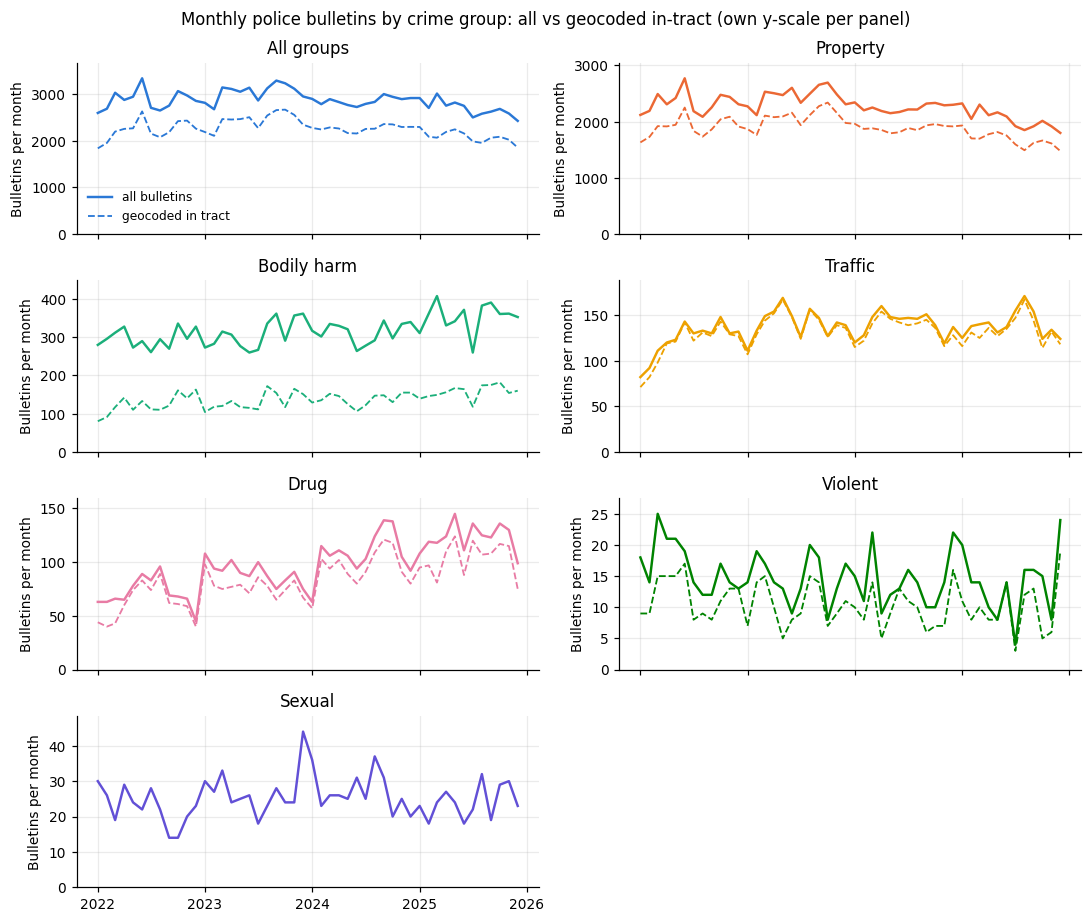

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(10, 8.5), sharex=True)
for ax, g in zip(axes.flat, TEMPORAL_GROUPS):
    ax.plot(all_bul.index, all_bul[g], color=GROUP_COLORS[g], lw=1.6, label="all bulletins")
    if g in in_tract:
        ax.plot(in_tract.index, in_tract[g], color=GROUP_COLORS[g], lw=1.2, ls="--", label="geocoded in tract")
    ax.set_ylim(0, all_bul[g].max() * 1.1)
    ax.set_title(GROUP_LABEL[g])
    ax.set_ylabel("Bulletins per month")
axes[0, 0].legend(frameon=False, fontsize=8)
axes.flat[-1].set_axis_off()
fig.suptitle("Monthly police bulletins by crime group: all vs geocoded in-tract (own y-scale per panel)")
fig.tight_layout()
save(fig, "monthly_all_vs_in_tract")

## STL decomposition

`STL(y, period=12, robust=True).fit()` gives y = T + S + R. The robustness weights (`res.weights`, 1 = ordinary, near 0 = downweighted) flag months the fit treats as outliers.

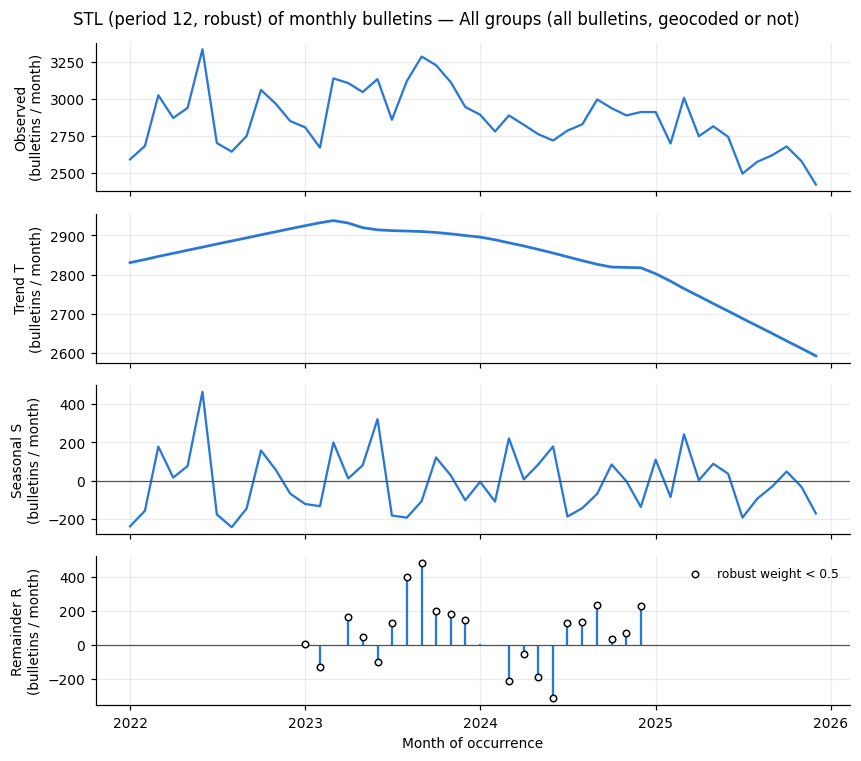

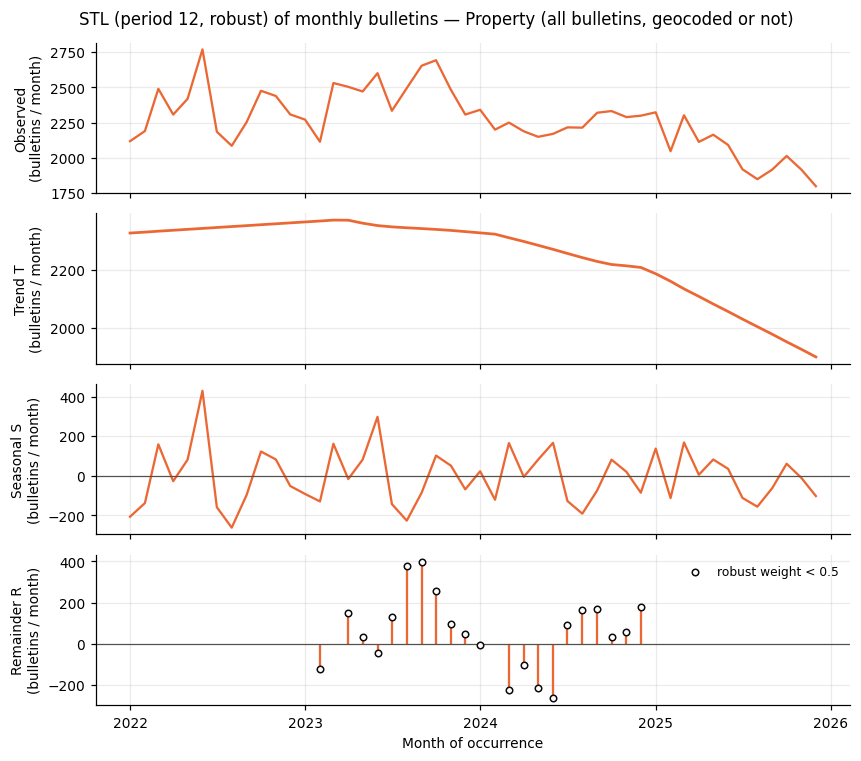

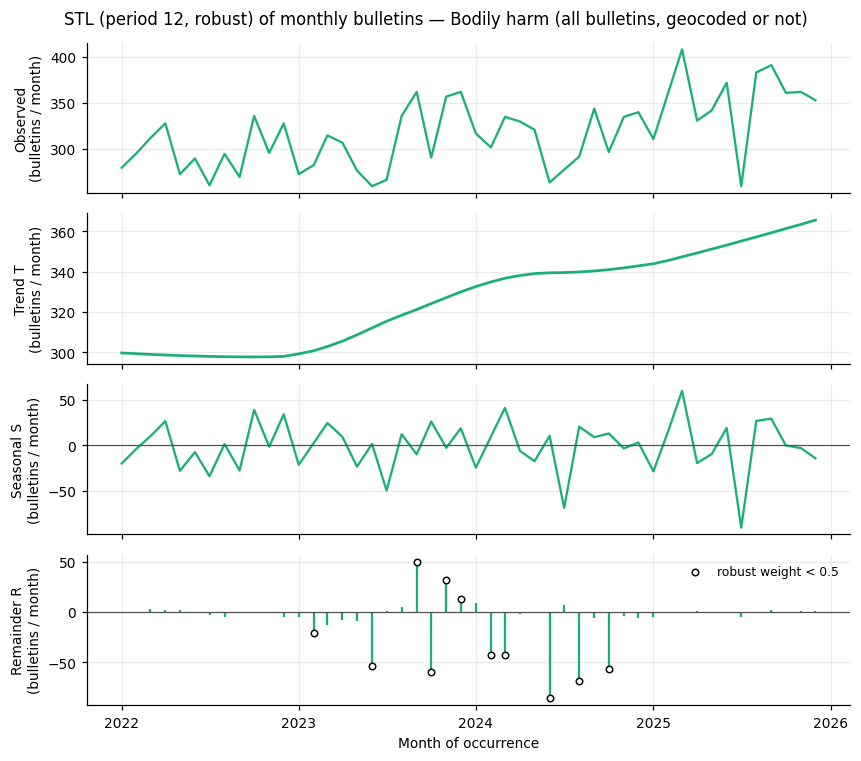

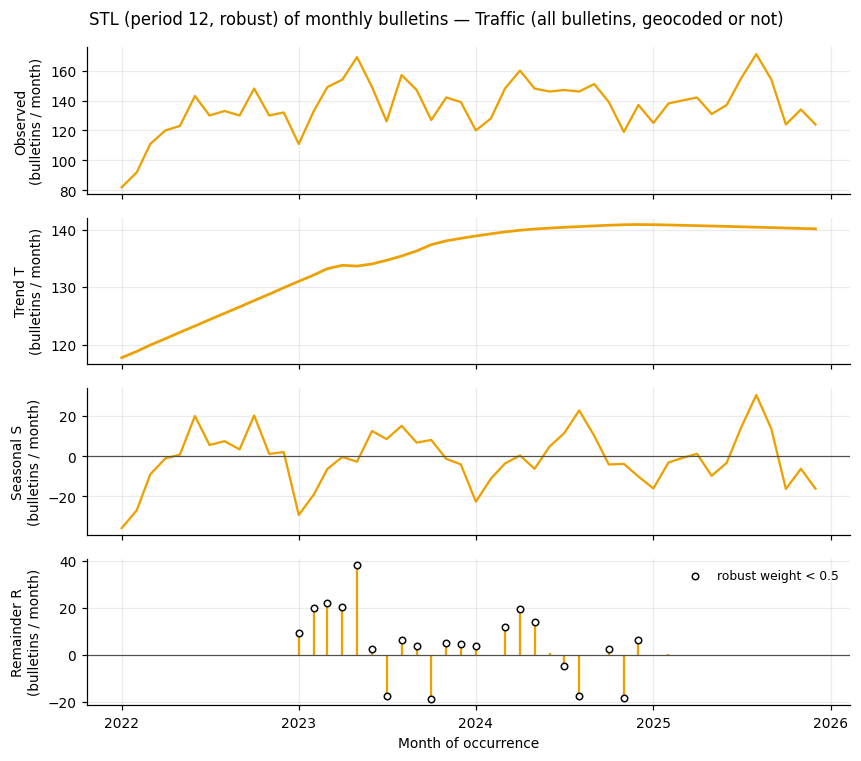

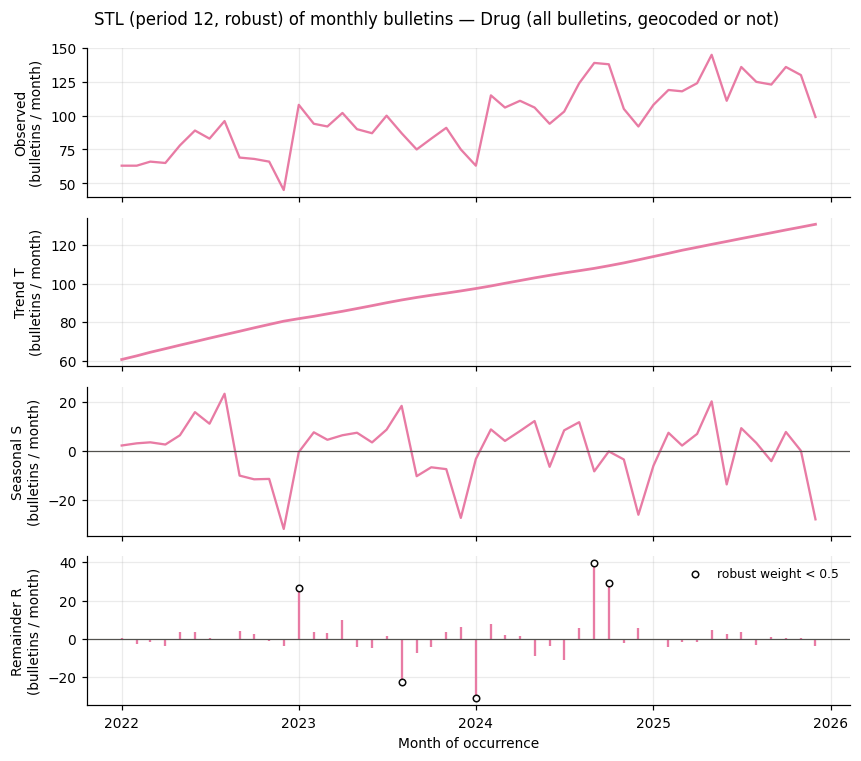

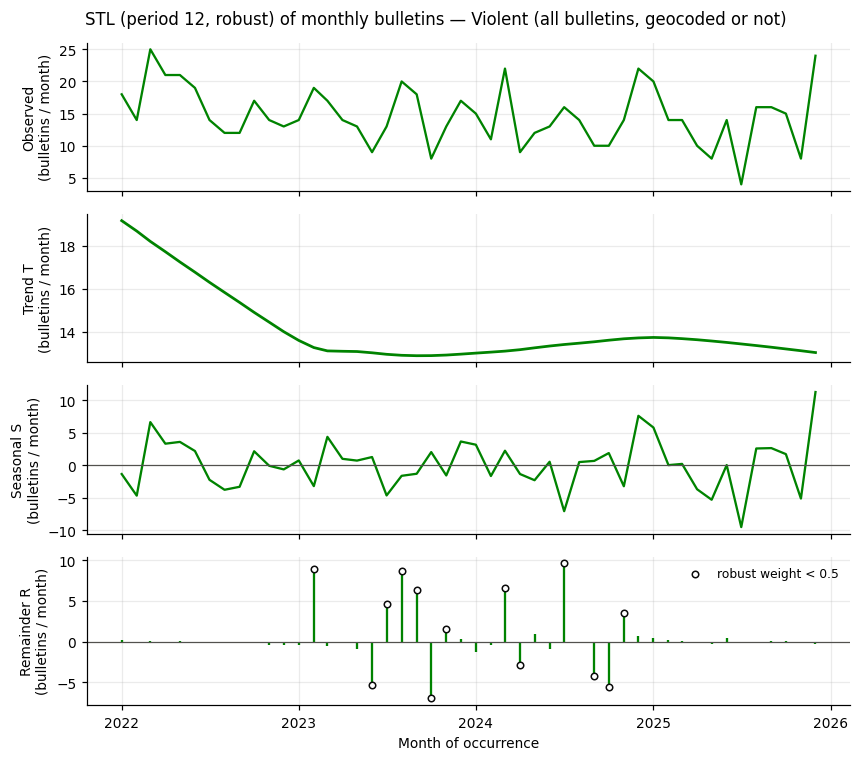

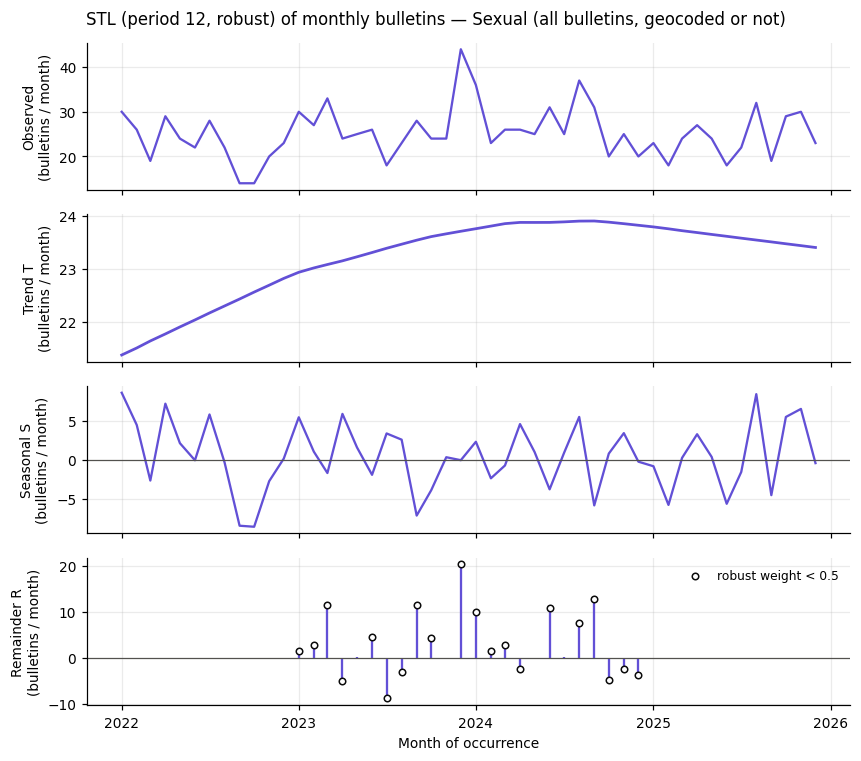

In [4]:
fits = {}
for kind, df in series.items():
    for g in df.columns:
        fits[(kind, g)] = STL(df[g].astype(float), period=PERIOD, robust=ROBUST).fit()

comp = pd.concat({f"{k}|{g}": pd.DataFrame({"observed": r.observed, "trend": r.trend, "seasonal": r.seasonal,
                                            "resid": r.resid, "robust_weight": r.weights})
                  for (k, g), r in fits.items()}, axis=1)
comp.to_csv(OUT / "stl_components.csv")

for g in TEMPORAL_GROUPS:
    r = fits[("all_bulletins", g)]
    fig, axes = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
    axes[0].plot(r.observed.index, r.observed, color=GROUP_COLORS[g], lw=1.5)
    axes[0].set_ylabel("Observed\n(bulletins / month)")
    axes[1].plot(r.trend.index, r.trend, color=GROUP_COLORS[g], lw=1.8)
    axes[1].set_ylabel("Trend T\n(bulletins / month)")
    axes[2].plot(r.seasonal.index, r.seasonal, color=GROUP_COLORS[g], lw=1.5)
    axes[2].axhline(0, color="#52514e", lw=0.8)
    axes[2].set_ylabel("Seasonal S\n(bulletins / month)")
    axes[3].vlines(r.resid.index, 0, r.resid, color=GROUP_COLORS[g], lw=1.5)
    low = r.weights < 0.5
    axes[3].scatter(r.resid.index[low], r.resid[low], s=18, facecolor="white", edgecolor="#0b0b0b",
                    zorder=3, label="robust weight < 0.5")
    axes[3].axhline(0, color="#52514e", lw=0.8)
    axes[3].set_ylabel("Remainder R\n(bulletins / month)")
    if low.any():
        axes[3].legend(frameon=False, fontsize=8)
    axes[3].set_xlabel("Month of occurrence")
    fig.suptitle(f"STL (period 12, robust) of monthly bulletins — {GROUP_LABEL[g]} (all bulletins, geocoded or not)")
    fig.tight_layout()
    save(fig, f"stl_{g}")

## Strength of trend and seasonality

Wang, Smith & Hyndman (2006); FPP3 §4.3 (no library function, so written out):

$$F_T = \max\!\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(T_t + R_t)}\right), \qquad
F_S = \max\!\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$

Both lie in [0, 1]; values near 1 mean the component dominates the remainder. Also reported: the seasonal amplitude (max − min of S, bulletins/month), the peak and trough calendar months of S, and the trend change from the first to the last month.

In [5]:
def strengths(r):
    vR = np.var(r.resid, ddof=1)
    return (max(0.0, 1 - vR / np.var(r.trend + r.resid, ddof=1)),
            max(0.0, 1 - vR / np.var(r.seasonal + r.resid, ddof=1)))

rows = []
for (kind, g), r in fits.items():
    ft, fs = strengths(r)
    s_mean = r.seasonal.groupby(r.seasonal.index.month).mean()
    rows.append({"series": kind, "group": g, "mean_per_month": r.observed.mean(),
                 "trend_strength_FT": ft, "seasonal_strength_FS": fs,
                 "seasonal_amplitude": r.seasonal.max() - r.seasonal.min(),
                 "seasonal_peak_month": int(s_mean.idxmax()), "seasonal_trough_month": int(s_mean.idxmin()),
                 "trend_first": r.trend.iloc[0], "trend_last": r.trend.iloc[-1],
                 "trend_change_%": 100 * (r.trend.iloc[-1] / r.trend.iloc[0] - 1),
                 "months_robust_weight_lt_0.5": int((r.weights < 0.5).sum())})
strength = pd.DataFrame(rows)
strength.to_csv(OUT / "stl_strength.csv", index=False)
strength.round(2)

,series,group,mean_per_month,trend_strength_FT,seasonal_strength_FS,seasonal_amplitude,seasonal_peak_month,seasonal_trough_month,trend_first,trend_last,trend_change_%,months_robust_weight_lt_0.5
0,all_bulletins,all,2860.90,0.40,0.34,705.83,6,7,2830.44,2592.72,-8.40,21
1,all_bulletins,property,2269.04,0.60,0.36,691.34,6,8,2325.20,1900.77,-18.25,21
2,all_bulletins,bodily_harm,317.62,0.43,0.42,150.47,3,7,299.75,365.53,21.95,11
3,all_bulletins,traffic,136.27,0.31,0.53,66.28,8,1,117.73,140.14,19.03,21
4,all_bulletins,drug,98.02,0.79,0.51,54.92,8,12,60.56,130.76,115.91,5
5,all_bulletins,violent,14.71,0.15,0.41,20.76,12,7,19.16,13.05,-31.88,13
6,all_bulletins,sexual,25.23,0.07,0.18,17.20,4,9,21.37,23.40,9.53,20
7,in_tract,all,2247.06,0.52,0.45,748.23,6,2,2179.87,1986.85,-8.85,22
8,in_tract,property,1884.08,0.63,0.42,563.68,6,8,1881.08,1556.05,-17.28,14
9,in_tract,bodily_harm,137.29,0.40,0.37,73.18,10,7,121.14,165.18,36.35,9


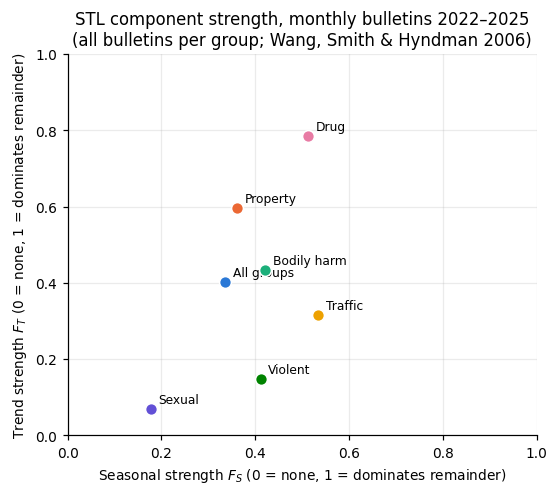

In [6]:
s = strength[strength["series"] == "all_bulletins"].set_index("group")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for g, row in s.iterrows():
    ax.scatter(row["seasonal_strength_FS"], row["trend_strength_FT"], s=60, color=GROUP_COLORS[g],
               edgecolor="white", zorder=3)
    ax.annotate(GROUP_LABEL[g], (row["seasonal_strength_FS"], row["trend_strength_FT"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Seasonal strength $F_S$ (0 = none, 1 = dominates remainder)")
ax.set_ylabel("Trend strength $F_T$ (0 = none, 1 = dominates remainder)")
ax.set_title("STL component strength, monthly bulletins 2022–2025\n(all bulletins per group; Wang, Smith & Hyndman 2006)")
save(fig, "stl_strength")

## Sensitivity: robust vs non-robust STL on a 4-cycle series

With only 48 months each calendar-month sub-series has 4 values, and statsmodels' default seasonal window (7) spans all of them. The robust iterations can then down-weight the middle years to almost zero, after which the seasonal loess passes (almost) exactly through the first and last year: the remainder becomes ~0 in 2022 and 2025 and all irregular variation is pushed into 2023–2024 (visible in the plots above). The table counts months whose remainder is below 1 bulletin in absolute value and compares the strengths with an ordinary (`robust=False`) STL, same windows.

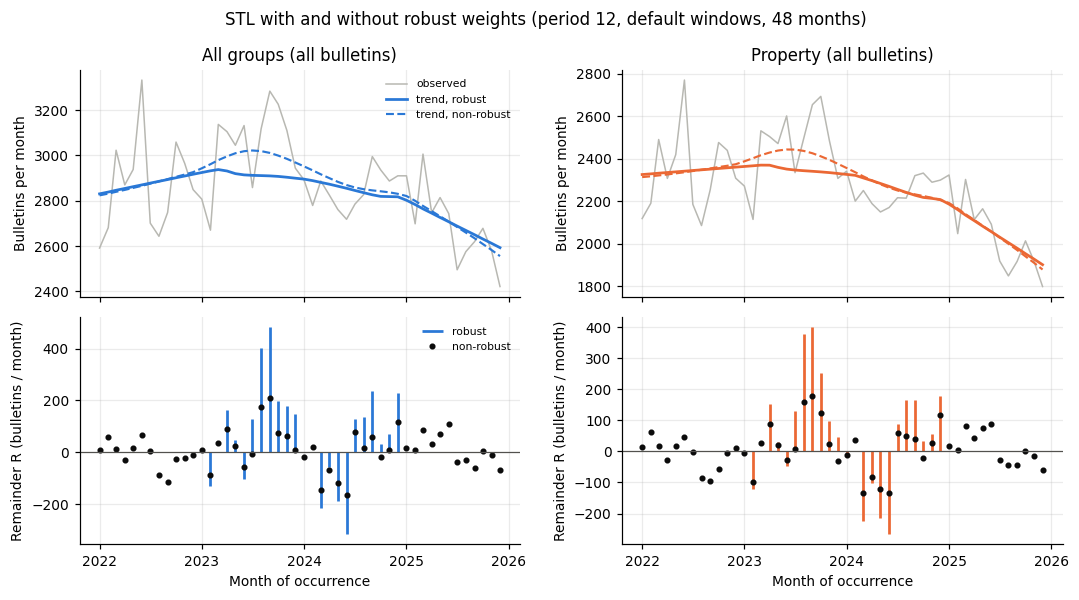

,series,group,robust_months_|R|<1,robust_months_weight<0.5,nonrobust_months_|R|<1,FT_robust,FT_nonrobust,FS_robust,FS_nonrobust,trend_change_%_robust,trend_change_%_nonrobust
0,all_bulletins,all,26,21,0,0.40,0.75,0.34,0.76,-8.40,-9.50
1,all_bulletins,property,27,21,1,0.60,0.84,0.36,0.75,-18.25,-18.81
2,all_bulletins,bodily_harm,12,11,3,0.43,0.74,0.42,0.78,21.95,23.31
3,all_bulletins,traffic,27,21,9,0.31,0.69,0.53,0.80,19.03,28.33
4,all_bulletins,drug,7,5,4,0.79,0.86,0.51,0.67,115.91,120.65
5,all_bulletins,violent,33,13,18,0.15,0.21,0.41,0.68,-31.88,-27.35
6,all_bulletins,sexual,28,20,11,0.07,0.29,0.18,0.57,9.53,9.35
7,in_tract,all,26,22,2,0.52,0.81,0.45,0.77,-8.85,-8.29
8,in_tract,property,3,14,2,0.63,0.85,0.42,0.74,-17.28,-16.73
9,in_tract,bodily_harm,14,9,3,0.40,0.68,0.37,0.76,36.35,39.50


In [7]:
rows = []
for (kind, g), r in list(fits.items()):
    r0 = STL(series[kind][g].astype(float), period=PERIOD, robust=False).fit()
    ft, fs = strengths(r)
    ft0, fs0 = strengths(r0)
    rows.append({"series": kind, "group": g,
                 "robust_months_|R|<1": int((r.resid.abs() < 1).sum()),
                 "robust_months_weight<0.5": int((r.weights < 0.5).sum()),
                 "nonrobust_months_|R|<1": int((r0.resid.abs() < 1).sum()),
                 "FT_robust": ft, "FT_nonrobust": ft0, "FS_robust": fs, "FS_nonrobust": fs0,
                 "trend_change_%_robust": 100 * (r.trend.iloc[-1] / r.trend.iloc[0] - 1),
                 "trend_change_%_nonrobust": 100 * (r0.trend.iloc[-1] / r0.trend.iloc[0] - 1)})
    fits[(kind + "_nonrobust", g)] = r0
sens = pd.DataFrame(rows)
sens.to_csv(OUT / "stl_robust_vs_nonrobust.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(10, 5.5), sharex=True)
for j, g in enumerate(["all", "property"]):
    r, r0 = fits[("all_bulletins", g)], fits[("all_bulletins_nonrobust", g)]
    axes[0, j].plot(r.observed.index, r.observed, color="#b8b8b2", lw=1, label="observed")
    axes[0, j].plot(r.trend.index, r.trend, color=GROUP_COLORS[g], lw=1.8, label="trend, robust")
    axes[0, j].plot(r0.trend.index, r0.trend, color=GROUP_COLORS[g], lw=1.4, ls="--", label="trend, non-robust")
    axes[0, j].set_title(GROUP_LABEL[g] + " (all bulletins)")
    axes[0, j].set_ylabel("Bulletins per month")
    axes[1, j].vlines(r.resid.index, 0, r.resid, color=GROUP_COLORS[g], lw=1.8, label="robust")
    axes[1, j].plot(r0.resid.index, r0.resid, "o", ms=3, color="#0b0b0b", label="non-robust")
    axes[1, j].axhline(0, color="#52514e", lw=0.8)
    axes[1, j].set_ylabel("Remainder R (bulletins / month)")
    axes[1, j].set_xlabel("Month of occurrence")
axes[0, 0].legend(frameon=False, fontsize=7); axes[1, 0].legend(frameon=False, fontsize=7)
fig.suptitle("STL with and without robust weights (period 12, default windows, 48 months)")
fig.tight_layout()
save(fig, "stl_robust_vs_nonrobust")
sens.round(2)

## Mann–Kendall trend test and Sen's slope

On each monthly series (48 values): `pymannkendall.original_test`, `hamed_rao_modification_test` and `seasonal_test(period=12)`. Sen's slope is the median of pairwise slopes, in bulletins per month per month (×12 → per year). The seasonal test's slope (pymannkendall `seasonal_sens_slope`) is the median of slopes between the same calendar month in different years, i.e. the yearly change of one month's count, reported in its own column.

In [8]:
rows = []
for kind, df in series.items():
    for g in df.columns:
        y = df[g].to_numpy(dtype=float)
        o = mk.original_test(y, alpha=ALPHA)
        h = mk.hamed_rao_modification_test(y, alpha=ALPHA)
        sz = mk.seasonal_test(y, period=PERIOD, alpha=ALPHA)
        rows.append({"series": kind, "group": g,
                     "mk_trend": o.trend, "mk_tau": o.Tau, "mk_z": o.z, "mk_p": o.p,
                     "sen_slope_per_month": o.slope, "sen_slope_per_year": 12 * o.slope,
                     "sen_slope_%_of_mean_per_year": 100 * 12 * o.slope / y.mean(),
                     "hamed_rao_z": h.z, "hamed_rao_p": h.p, "hamed_rao_trend": h.trend,
                     "seasonal_mk_z": sz.z, "seasonal_mk_p": sz.p, "seasonal_mk_trend": sz.trend,
                     "seasonal_sen_slope_per_year": sz.slope})
mkt = pd.DataFrame(rows)
mkt.to_csv(OUT / "mann_kendall_sen.csv", index=False)
mkt.round(4)

,series,group,mk_trend,mk_tau,mk_z,mk_p,sen_slope_per_month,sen_slope_per_year,sen_slope_%_of_mean_per_year,hamed_rao_z,hamed_rao_p,hamed_rao_trend,seasonal_mk_z,seasonal_mk_p,seasonal_mk_trend,seasonal_sen_slope_per_year
0,all_bulletins,all,decreasing,-0.2553,-2.5511,0.0107,-6.0000,-72.0000,-2.5167,-1.8958,0.0580,no trend,-1.8631,0.0624,no trend,-63.5000
1,all_bulletins,property,decreasing,-0.3821,-3.8220,0.0001,-9.3515,-112.2176,-4.9456,-2.8212,0.0048,decreasing,-3.0398,0.0024,decreasing,-87.0000
2,all_bulletins,bodily_harm,increasing,0.3848,3.8508,0.0001,1.5683,18.8199,5.9252,3.8508,0.0001,increasing,3.6281,0.0003,increasing,13.7500
3,all_bulletins,traffic,no trend,0.1871,1.8678,0.0618,0.3571,4.2857,3.1450,1.4557,0.1455,no trend,1.6670,0.0955,no trend,5.5000
4,all_bulletins,drug,increasing,0.5816,5.8250,0.0000,1.3516,16.2198,16.5473,6.0979,0.0000,increasing,5.8419,0.0000,increasing,17.1667
5,all_bulletins,violent,no trend,-0.1676,-1.6821,0.0926,-0.0851,-1.0217,-6.9467,-1.6821,0.0926,no trend,-0.8911,0.3729,no trend,-1.0000
6,all_bulletins,sexual,no trend,0.0115,0.1070,0.9148,0.0000,0.0000,0.0000,0.1070,0.9148,no trend,0.7000,0.4839,no trend,1.0000
7,in_tract,all,no trend,-0.1959,-1.9554,0.0505,-5.0788,-60.9459,-2.7122,-1.2261,0.2202,no trend,-1.6670,0.0955,no trend,-49.0000
8,in_tract,property,decreasing,-0.3200,-3.1998,0.0014,-7.1064,-85.2773,-4.5262,-1.8191,0.0689,no trend,-2.6476,0.0081,decreasing,-78.0000
9,in_tract,bodily_harm,increasing,0.4486,4.4904,0.0000,1.1429,13.7143,9.9892,4.4904,0.0000,increasing,3.7443,0.0002,increasing,10.4167


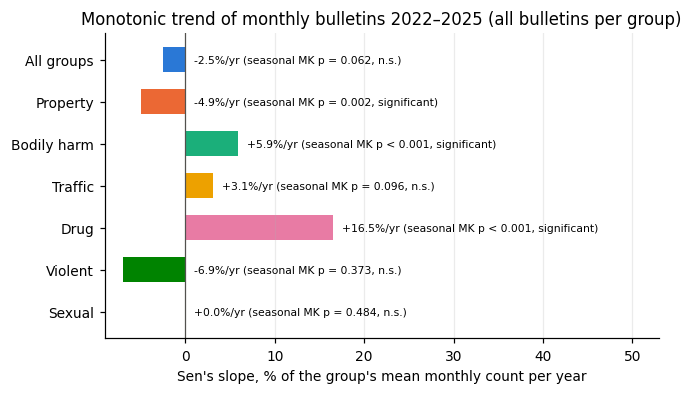

In [9]:
d = mkt[mkt["series"] == "all_bulletins"].set_index("group").loc[TEMPORAL_GROUPS]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
yy = np.arange(len(d))[::-1]
ax.barh(yy, d["sen_slope_%_of_mean_per_year"], color=[GROUP_COLORS[g] for g in d.index], height=0.6)
for yi, (g, row) in zip(yy, d.iterrows()):
    star = "significant" if row["seasonal_mk_p"] < ALPHA else "n.s."
    v = row["sen_slope_%_of_mean_per_year"]
    pv = row["seasonal_mk_p"]
    ptxt = "p < 0.001" if pv < 0.001 else f"p = {pv:.3f}"
    ax.text(max(v, 0) + 1, yi, f"{v:+.1f}%/yr (seasonal MK {ptxt}, {star})", va="center", ha="left", fontsize=7)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(yy, [GROUP_LABEL[g] for g in d.index])
lo = min(d["sen_slope_%_of_mean_per_year"].min(), 0) * 1.3
ax.set_xlim(lo, d["sen_slope_%_of_mean_per_year"].max() * 3.2)
ax.set_xlabel("Sen's slope, % of the group's mean monthly count per year")
ax.set_title("Monotonic trend of monthly bulletins 2022–2025 (all bulletins per group)")
ax.grid(axis="y", visible=False)
save(fig, "sen_slope_by_group")

## Reporting lag check

Time is the occurrence date; bulletins registered after the data extract are missing. The registration delay (`DATA_REGISTRO − DATA_OCORRENCIA_BO`) of the bulletins we do have shows how much of a month is usually registered late.

In [10]:
bb = wh.bulletins(CrimeQuery(unit="city"))          # every bulletin in the window, geocoded or not
delay = (bb["registration_date"] - bb["occurrence_date"]).dt.days
lag = pd.Series({"median_delay_days": delay.median(), "share_registered_>30d_%": 100 * (delay > 30).mean(),
                 "share_registered_>90d_%": 100 * (delay > 90).mean(),
                 "latest_registration": bb["registration_date"].max().date()})
lag.to_frame("value")

,value
median_delay_days,1.0
share_registered_>30d_%,3.477932
share_registered_>90d_%,1.201547
latest_registration,2025-12-31


## Findings

In [11]:
for kind in series:
    st = strength[strength["series"] == kind].set_index("group")
    m = mkt[mkt["series"] == kind].set_index("group")
    print(f"--- {kind}")
    for g in st.index:
        print(f"{g:12s} mean {st.loc[g,'mean_per_month']:7.1f}/mo  F_T {st.loc[g,'trend_strength_FT']:.2f}  "
              f"F_S {st.loc[g,'seasonal_strength_FS']:.2f}  trend {st.loc[g,'trend_change_%']:+6.1f}%  "
              f"S peak/trough month {st.loc[g,'seasonal_peak_month']}/{st.loc[g,'seasonal_trough_month']}  "
              f"Sen {m.loc[g,'sen_slope_per_year']:+7.1f}/yr ({m.loc[g,'sen_slope_%_of_mean_per_year']:+.1f}%)  "
              f"MK p {m.loc[g,'mk_p']:.4f}  HR p {m.loc[g,'hamed_rao_p']:.4f}  seasonal MK p {m.loc[g,'seasonal_mk_p']:.4f}")

--- all_bulletins
all          mean  2860.9/mo  F_T 0.40  F_S 0.34  trend   -8.4%  S peak/trough month 6/7  Sen   -72.0/yr (-2.5%)  MK p 0.0107  HR p 0.0580  seasonal MK p 0.0624
property     mean  2269.0/mo  F_T 0.60  F_S 0.36  trend  -18.3%  S peak/trough month 6/8  Sen  -112.2/yr (-4.9%)  MK p 0.0001  HR p 0.0048  seasonal MK p 0.0024
bodily_harm  mean   317.6/mo  F_T 0.43  F_S 0.42  trend  +21.9%  S peak/trough month 3/7  Sen   +18.8/yr (+5.9%)  MK p 0.0001  HR p 0.0001  seasonal MK p 0.0003
traffic      mean   136.3/mo  F_T 0.31  F_S 0.53  trend  +19.0%  S peak/trough month 8/1  Sen    +4.3/yr (+3.1%)  MK p 0.0618  HR p 0.1455  seasonal MK p 0.0955
drug         mean    98.0/mo  F_T 0.79  F_S 0.51  trend +115.9%  S peak/trough month 8/12  Sen   +16.2/yr (+16.5%)  MK p 0.0000  HR p 0.0000  seasonal MK p 0.0000
violent      mean    14.7/mo  F_T 0.15  F_S 0.41  trend  -31.9%  S peak/trough month 12/7  Sen    -1.0/yr (-6.9%)  MK p 0.0926  HR p 0.0926  seasonal MK p 0.3729
sexual       

_Written from the numbers printed above (rerun → recheck)._

- **Levels.** 137,323 bulletins in 2022–2025 (2,861 / month); 107,859 of them geocoded in a tract (2,247 / month). Property is 79 % of all bulletins; violent averages 15 / month (10 geocoded) and sexual 25 / month (none geocoded).
- **Trend (Mann–Kendall + Sen, all bulletins).** Property falls (Sen −112 bulletins / year, −4.9 % of its mean per year; MK p = 0.0001, Hamed–Rao p = 0.005, seasonal MK p = 0.002). Bodily harm rises (+18.8 / year, +5.9 %; all three tests p ≤ 0.0003) and drug rises steeply (+16.2 / year, +16.5 %; STL trend +116 % from first to last month; all p < 0.0001). Traffic, violent and sexual show no significant monotonic trend at α = 0.05 on any of the three tests. For *all* bulletins the plain MK test is significant (p = 0.011, −2.5 % / year) but not after the Hamed–Rao autocorrelation correction (p = 0.058) or the seasonal test (p = 0.062): the city-wide decline is not robust. The in-tract series give the same signs; there, property is significant on MK (p = 0.001) and seasonal MK (p = 0.008) but not Hamed–Rao (p = 0.069), and violent becomes significant only under Hamed–Rao (p = 0.014; the correction can shrink the variance when the lag correlations are negative).
- **STL trend.** Rises into early 2023 and declines afterwards for all and property (−8 % and −18 % first-to-last month); the end of the trend is a loess extrapolation and the last months may be depressed by reporting lag, although only 3.5 % of in-window bulletins were registered more than 30 days after occurrence and 1.2 % more than 90 days (median delay 1 day).
- **Seasonality.** The seasonal component is of the same order as the trend (robust F_S 0.18–0.56, F_T 0.07–0.79); drug has the strongest trend (F_T 0.79) and traffic the strongest seasonality (F_S 0.53, peak in August, trough in January). Peak / trough months of the other groups are not stable across the four years.
- **Limitation found: robust STL on 4 cycles.** With 48 months, the robust fit drives the remainder to |R| < 1 bulletin in 26 of 48 months of the all-groups series (21 months with robust weight < 0.5), mostly in 2022 and 2025, and loads all irregularity on 2023–2024. The non-robust STL gives remainders spread over all months and much higher strengths (all groups F_T 0.75, F_S 0.76 vs 0.40 / 0.34 robust). The trend *direction and size* agree (−9.5 % vs −8.4 % for all; −18.8 % vs −18.3 % for property), but **F_T / F_S are not robust to this choice** and should not be quoted without it. Four seasonal cycles are too few to estimate a seasonal pattern reliably with either fit.